# Semiconductor Wafer Yield Prediction on Real Fab Data (SECOM)
**Business question:** can process sensor readings warn us which production lots will fail the final quality test, so engineers inspect only the risky ones?

**Data:** SECOM from UCI. It is **real data** from a semiconductor manufacturing line: 1,567 production lots, 590 anonymised sensor readings, a pass/fail label and a timestamp. Only about 6.6% of lots fail.

**What makes this project honest and strong:**
1. Time-based split (train on past, test on future), like real life. No random shuffle.
2. All cleaning, selection and scaling happen *inside* the pipeline, so nothing leaks from test data.
3. No oversampling before splitting (a common mistake in SECOM papers).
4. Results are judged by PR-AUC, lift in top-risk lots, bootstrap confidence intervals, and business cost.

Run all cells top to bottom (Runtime > Run all). Expect modest scores. SECOM is a hard dataset, and the honest result is part of the story.

In [1]:
!pip -q install shap

In [2]:
import os, json, sqlite3, warnings, zipfile, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, shap
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate, RandomizedSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
                             RocCurveDisplay, PrecisionRecallDisplay)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("results/figures", exist_ok=True)
os.makedirs("model", exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Load the real SECOM data from UCI

In [3]:
def _try(url, dest):
    try:
        urllib.request.urlretrieve(url, dest)
        return True
    except Exception as e:
        print("Could not download", url, "->", type(e).__name__)
        return False

def load_secom():
    if not (os.path.exists("secom.data") and os.path.exists("secom_labels.data")):
        ok = _try("https://archive.ics.uci.edu/static/public/179/secom.zip", "secom.zip")
        if ok:
            with zipfile.ZipFile("secom.zip") as z:
                z.extractall(".")
        else:
            base = "https://archive.ics.uci.edu/ml/machine-learning-databases/secom/"
            ok = _try(base + "secom.data", "secom.data") and _try(base + "secom_labels.data", "secom_labels.data")
        if not os.path.exists("secom.data"):
            raise RuntimeError("Download failed. Download secom.zip from https://archive.ics.uci.edu/dataset/179/secom, "
                               "unzip it, and upload secom.data and secom_labels.data to the Colab files panel. Then re-run.")
    X = pd.read_csv("secom.data", sep=r"\s+", header=None, na_values="NaN")
    X.columns = [f"s{i+1:03d}" for i in range(X.shape[1])]
    lab = pd.read_csv("secom_labels.data", sep=" ", header=None, names=["label", "ts"], quotechar='"')
    ts = pd.to_datetime(lab["ts"].str.strip('"'), format="%d/%m/%Y %H:%M:%S")
    return X, (lab["label"] == 1).astype(int).rename("failure"), ts.rename("ts")

X_all, y_all, ts_all = load_secom()
order = np.argsort(ts_all.values, kind="stable")          # sort by time
X_all, y_all, ts_all = (a.iloc[order].reset_index(drop=True) for a in (X_all, y_all, ts_all))

print("Lots:", len(X_all), "| Sensors:", X_all.shape[1])
print(f"Failures: {int(y_all.sum())} ({y_all.mean()*100:.2f}%)")
print("Date range:", ts_all.min(), "to", ts_all.max())
print("Missing cells:", f"{X_all.isna().mean().mean()*100:.2f}%")
X_all.iloc[:3, :6]

Lots: 1567 | Sensors: 590
Failures: 104 (6.64%)
Date range: 2008-07-19 11:55:00 to 2008-10-17 06:07:00
Missing cells: 4.54%


,s001,s002,s003,s004,s005,s006
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0


## 2. Time-based split
First 70% of lots (oldest) = train, next 15% = validation (choose alert threshold), last 15% (newest) = test.

In [4]:
n = len(X_all); i1, i2 = int(n * 0.70), int(n * 0.85)
X_train, y_train, ts_train = X_all.iloc[:i1], y_all.iloc[:i1], ts_all.iloc[:i1]
X_val,   y_val,   ts_val   = X_all.iloc[i1:i2], y_all.iloc[i1:i2], ts_all.iloc[i1:i2]
X_test,  y_test,  ts_test  = X_all.iloc[i2:], y_all.iloc[i2:], ts_all.iloc[i2:]

split_info = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "lots": [len(y_train), len(y_val), len(y_test)],
    "failures": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "failure_rate_pct": [round(y.mean()*100, 2) for y in (y_train, y_val, y_test)],
    "from": [ts_train.min(), ts_val.min(), ts_test.min()],
    "to": [ts_train.max(), ts_val.max(), ts_test.max()]})
split_info.to_csv("results/split_info.csv", index=False)
split_info

,set,lots,failures,failure_rate_pct,from,to
0,train,1096,78,7.12,2008-07-19 11:55:00,2008-09-26 02:26:00
1,validation,235,17,7.23,2008-09-26 03:12:00,2008-10-05 18:59:00
2,test,236,9,3.81,2008-10-05 19:45:00,2008-10-17 06:07:00


## 3. SQL analysis (SQLite)
Same questions a process-engineering team would ask, answered in SQL.

In [5]:
lots = pd.DataFrame({"lot_id": range(1, len(X_all)+1), "ts": ts_all.dt.strftime("%Y-%m-%d %H:%M:%S"),
                     "failure": y_all, "n_missing": X_all.isna().sum(axis=1)})
con = sqlite3.connect("results/secom.db")
lots.to_sql("lots", con, if_exists="replace", index=False)

queries = {
"weekly_failure_rate": """
WITH weekly AS (
  SELECT strftime('%Y-W%W', ts) AS week, COUNT(*) AS lots, SUM(failure) AS fails
  FROM lots GROUP BY week)
SELECT week, lots, fails,
       ROUND(100.0 * fails / lots, 2) AS fail_rate_pct,
       ROUND(100.0 * SUM(fails) OVER (ORDER BY week ROWS BETWEEN 3 PRECEDING AND CURRENT ROW)
                   / SUM(lots)  OVER (ORDER BY week ROWS BETWEEN 3 PRECEDING AND CURRENT ROW), 2) AS rolling_4wk_fail_rate_pct
FROM weekly ORDER BY week""",

"failure_by_shift": """
SELECT CASE WHEN CAST(strftime('%H', ts) AS INT) BETWEEN 6 AND 13 THEN '1: morning (06-13)'
            WHEN CAST(strftime('%H', ts) AS INT) BETWEEN 14 AND 21 THEN '2: evening (14-21)'
            ELSE '3: night (22-05)' END AS shift,
       COUNT(*) AS lots, SUM(failure) AS fails,
       ROUND(100.0 * SUM(failure) / COUNT(*), 2) AS fail_rate_pct
FROM lots GROUP BY shift ORDER BY shift""",

"failure_by_missing_sensor_quartile": """
WITH q AS (SELECT failure, n_missing, NTILE(4) OVER (ORDER BY n_missing) AS quartile FROM lots)
SELECT quartile, MIN(n_missing) AS min_missing_sensors, MAX(n_missing) AS max_missing_sensors,
       COUNT(*) AS lots, ROUND(100.0 * SUM(failure) / COUNT(*), 2) AS fail_rate_pct
FROM q GROUP BY quartile ORDER BY quartile""",

"failure_by_month": """
SELECT strftime('%Y-%m', ts) AS month, COUNT(*) AS lots, SUM(failure) AS fails,
       ROUND(100.0 * SUM(failure) / COUNT(*), 2) AS fail_rate_pct
FROM lots GROUP BY month ORDER BY month"""}

for name, q in queries.items():
    out = pd.read_sql(q, con)
    out.to_csv(f"results/sql_{name}.csv", index=False)
    print(f"--- {name} ---")
    display(out)
con.close()

--- weekly_failure_rate ---


,week,lots,fails,fail_rate_pct,rolling_4wk_fail_rate_pct
0,2008-W28,13,3,23.08,23.08
1,2008-W29,21,2,9.52,14.71
2,2008-W30,48,10,20.83,18.29
3,2008-W31,108,14,12.96,15.26
4,2008-W32,51,7,13.73,14.47
5,2008-W33,208,22,10.58,12.77
6,2008-W34,169,7,4.14,9.33
7,2008-W35,133,2,1.50,6.77
8,2008-W36,95,4,4.21,5.79
9,2008-W37,154,5,3.25,3.27


--- failure_by_shift ---


,shift,lots,fails,fail_rate_pct
0,1: morning (06-13),492,31,6.30
1,2: evening (14-21),568,40,7.04
2,3: night (22-05),507,33,6.51


--- failure_by_missing_sensor_quartile ---


,quartile,min_missing_sensors,max_missing_sensors,lots,fail_rate_pct
0,1,4,20,392,6.89
1,2,20,24,392,9.18
2,3,24,32,392,5.61
3,4,32,152,391,4.86


--- failure_by_month ---


,month,lots,fails,fail_rate_pct
0,2008-07,63,14,22.22
1,2008-08,555,51,9.19
2,2008-09,590,17,2.88
3,2008-10,359,22,6.13


## 4. Exploratory data analysis

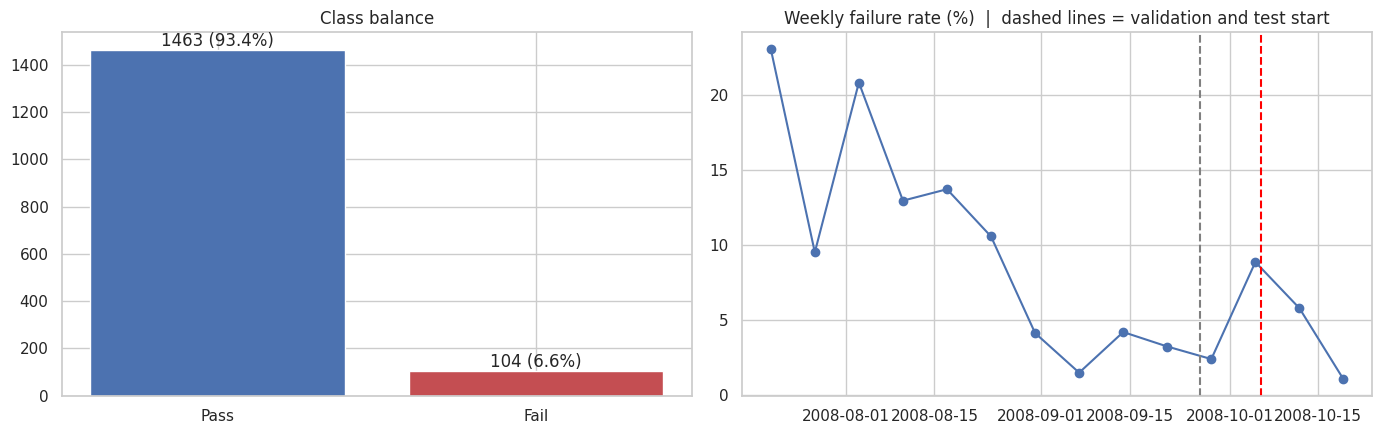

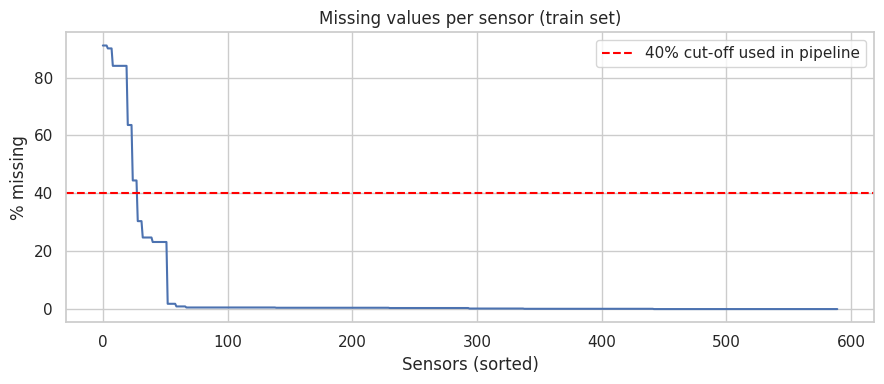

Sensors with >40% missing: 28 | constant sensors: 122 | total sensors: 590


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
counts = y_all.value_counts().sort_index()
ax[0].bar(["Pass", "Fail"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v} ({v/len(y_all)*100:.1f}%)", ha="center", va="bottom")
ax[0].set_title("Class balance")

weekly = pd.DataFrame({"ts": ts_all, "f": y_all}).set_index("ts").resample("W")["f"].agg(["mean", "count"])
ax[1].plot(weekly.index, weekly["mean"] * 100, marker="o")
ax[1].axvline(ts_val.min(), color="grey", ls="--"); ax[1].axvline(ts_test.min(), color="red", ls="--")
ax[1].set_title("Weekly failure rate (%)  |  dashed lines = validation and test start")
plt.tight_layout(); plt.savefig("results/figures/01_class_balance_and_drift.png", dpi=150); plt.show()

miss = (X_train.isna().mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(9, 4))
plt.plot(range(len(miss)), miss.values)
plt.axhline(40, color="red", ls="--", label="40% cut-off used in pipeline")
plt.xlabel("Sensors (sorted)"); plt.ylabel("% missing"); plt.title("Missing values per sensor (train set)"); plt.legend()
plt.tight_layout(); plt.savefig("results/figures/02_missingness.png", dpi=150); plt.show()

const = int((X_train.nunique() <= 1).sum())
print(f"Sensors with >40% missing: {(miss > 40).sum()} | constant sensors: {const} | total sensors: {X_train.shape[1]}")

## 5. Leakage-safe preprocessing pipeline
Steps (fit on training data only): drop sensors with >40% missing, median-impute, drop constant sensors, drop one of each highly correlated pair (|r| > 0.95), scale, keep the top-k sensors by F-test, then the model.

In [7]:
# Custom steps are saved in a small module, so the saved model can be loaded later (for example in a web app).
transformers_code = """
import numpy as np, pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class MissingFilter(BaseEstimator, TransformerMixin):
    def __init__(self, max_missing=0.4): self.max_missing = max_missing
    def fit(self, X, y=None):
        self.keep_ = pd.DataFrame(X).isna().mean().values <= self.max_missing
        return self
    def transform(self, X): return np.asarray(X, dtype=float)[:, self.keep_]
    def get_feature_names_out(self, input_features=None): return np.asarray(input_features)[self.keep_]

class CorrFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.95): self.threshold = threshold
    def fit(self, X, y=None):
        c = np.nan_to_num(np.abs(np.corrcoef(np.asarray(X, float), rowvar=False)))
        self.keep_ = ~(np.triu(c, k=1) > self.threshold).any(axis=0)
        return self
    def transform(self, X): return np.asarray(X, dtype=float)[:, self.keep_]
    def get_feature_names_out(self, input_features=None): return np.asarray(input_features)[self.keep_]
"""
with open("transformers.py", "w") as f:
    f.write(transformers_code)
import sys, importlib
sys.path.insert(0, os.getcwd()); importlib.invalidate_caches()
from transformers import MissingFilter, CorrFilter

def make_pipe(model, k=30):
    return Pipeline([("miss", MissingFilter(0.4)), ("imp", SimpleImputer(strategy="median")),
                     ("var", VarianceThreshold(0.0)), ("corr", CorrFilter(0.95)),
                     ("scale", StandardScaler()), ("select", SelectKBest(f_classif, k=k)), ("model", model)])

def kept_names(pipe, cols):
    names = np.asarray(cols)
    for _, step in pipe.steps[:-1]:
        names = step.get_feature_names_out(names)
    return names

pos_w = float((y_train == 0).sum() / (y_train == 1).sum())
candidates = {
    "Logistic Regression": make_pipe(LogisticRegression(C=0.05, class_weight="balanced", max_iter=3000)),
    "Random Forest": make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                                      n_jobs=-1, random_state=SEED)),
    "XGBoost": make_pipe(XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                                       scale_pos_weight=pos_w, eval_metric="aucpr", random_state=SEED, n_jobs=-1)),
}
pipe_demo = clone(candidates["XGBoost"]).fit(X_train, y_train)
print("Sensors after cleaning steps:", len(kept_names(pipe_demo[:-2], X_train.columns)), "| kept by selector:", pipe_demo["select"].k)

Sensors after cleaning steps: 268 | kept by selector: 30


## 6. Model comparison with time-series cross-validation
Each fold trains on the past and validates on the next block of time. PR-AUC is the main metric. A random model scores PR-AUC equal to the failure rate (about 0.07).

In [8]:
tscv = TimeSeriesSplit(n_splits=4)
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}

def cv_row(name, pipe):
    r = cross_validate(pipe, X_train, y_train, cv=tscv, scoring=scoring, n_jobs=1)
    return {"model": name, "cv_pr_auc": r["test_pr_auc"].mean(), "cv_pr_auc_std": r["test_pr_auc"].std(),
            "cv_roc_auc": r["test_roc_auc"].mean(), "cv_roc_auc_std": r["test_roc_auc"].std()}

rows = [cv_row(k, v) for k, v in candidates.items()]
rows.append({"model": "Random guess (reference)", "cv_pr_auc": float(y_train.mean()), "cv_pr_auc_std": 0.0,
             "cv_roc_auc": 0.5, "cv_roc_auc_std": 0.0})
pd.DataFrame(rows).round(4)

,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_roc_auc_std
0,Logistic Regression,0.1139,0.1120,0.4858,0.1545
1,Random Forest,0.1532,0.0375,0.6218,0.0750
2,XGBoost,0.1296,0.0553,0.6402,0.0830
3,Random guess (reference),0.0712,0.0000,0.5000,0.0000


## 7. Tune XGBoost (including how many sensors to keep)

In [9]:
param_dist = {"select__k": [15, 30, 50, 80], "model__max_depth": [2, 3, 4], "model__n_estimators": [100, 200, 300],
              "model__learning_rate": [0.02, 0.05, 0.1], "model__subsample": [0.6, 0.8, 1.0],
              "model__colsample_bytree": [0.5, 0.8, 1.0], "model__min_child_weight": [1, 3, 5]}
search = RandomizedSearchCV(candidates["XGBoost"], param_dist, n_iter=20, scoring="average_precision",
                            cv=tscv, random_state=SEED, n_jobs=1, refit=False)
search.fit(X_train, y_train)
tuned = clone(candidates["XGBoost"]).set_params(**search.best_params_)
candidates["XGBoost (tuned)"] = tuned
print("Best params:", search.best_params_)

rows.insert(-1, cv_row("XGBoost (tuned)", tuned))
cv_table = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
cv_table.to_csv("results/model_comparison_cv.csv", index=False)
cv_table.round(4)

Best params: {'select__k': 80, 'model__subsample': 0.6, 'model__n_estimators': 100, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}


,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_roc_auc_std
0,XGBoost (tuned),0.1900,0.1372,0.6857,0.0984
1,Random Forest,0.1532,0.0375,0.6218,0.0750
2,XGBoost,0.1296,0.0553,0.6402,0.0830
3,Logistic Regression,0.1139,0.1120,0.4858,0.1545
4,Random guess (reference),0.0712,0.0000,0.5000,0.0000


## 8. Final model: evaluate once on the future (test) data

Selected model: XGBoost (tuned)
{
  "roc_auc": 0.7048,
  "roc_auc_95ci": [
    0.6,
    0.807
  ],
  "pr_auc": 0.0661,
  "pr_auc_95ci": [
    0.034,
    0.135
  ],
  "random_guess_pr_auc": 0.0381,
  "test_lots": 236,
  "test_failures": 9
}


,inspect_top_pct_of_lots,lots_inspected,failures_caught,share_of_failures_caught_pct,lift_vs_random
0,5,12,0,0.0,0.00
1,10,24,1,11.1,1.11
2,20,48,2,22.2,1.11
3,30,71,4,44.4,1.48
4,50,118,9,100.0,2.00


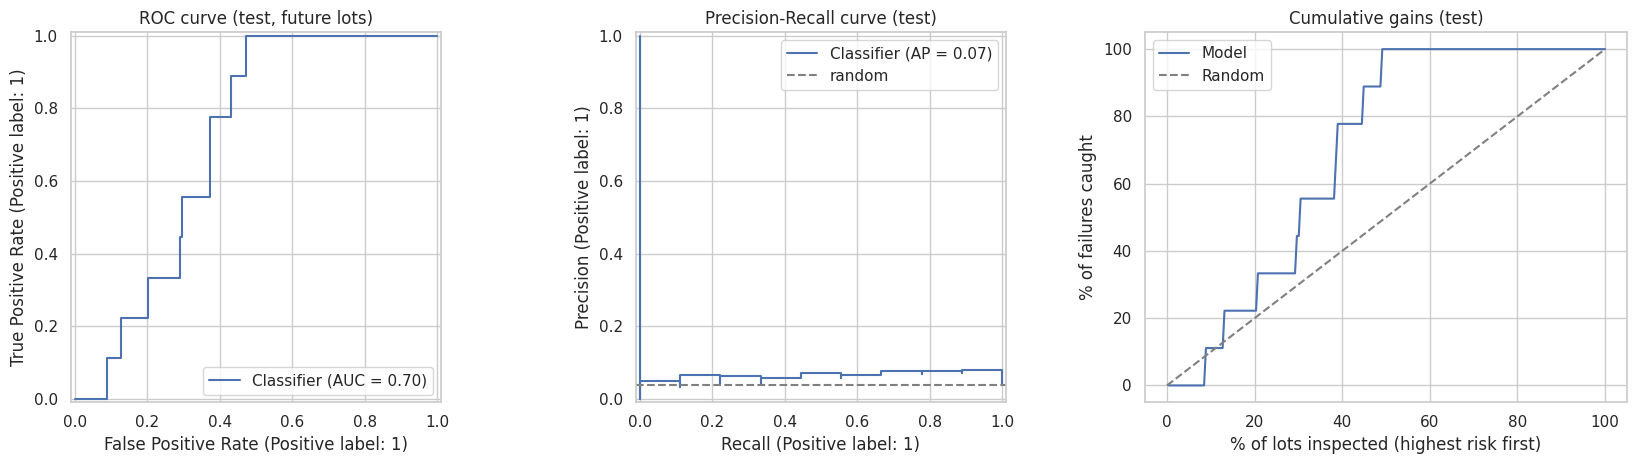

In [10]:
real = cv_table[cv_table["model"].isin(candidates)]
best_name = real.iloc[0]["model"]
final = clone(candidates[best_name]).fit(X_train, y_train)
print("Selected model:", best_name)

val_p, test_p = final.predict_proba(X_val)[:, 1], final.predict_proba(X_test)[:, 1]

def boot_ci(y, p, metric, n_boot=1000):
    rng = np.random.default_rng(SEED); y = np.asarray(y); p = np.asarray(p); vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if 0 < y[idx].sum() < len(idx):
            vals.append(metric(y[idx], p[idx]))
    return [round(float(v), 3) for v in np.percentile(vals, [2.5, 97.5])]

test_metrics = {"roc_auc": round(roc_auc_score(y_test, test_p), 4), "roc_auc_95ci": boot_ci(y_test, test_p, roc_auc_score),
                "pr_auc": round(average_precision_score(y_test, test_p), 4), "pr_auc_95ci": boot_ci(y_test, test_p, average_precision_score),
                "random_guess_pr_auc": round(float(y_test.mean()), 4), "test_lots": int(len(y_test)), "test_failures": int(y_test.sum())}
print(json.dumps(test_metrics, indent=2))

# Gains / lift: if engineers inspect only the top-risk lots, how many failures do they catch?
order_ = np.argsort(-test_p); y_sorted = np.asarray(y_test)[order_]
gain_rows = []
for pct in [5, 10, 20, 30, 50]:
    k = int(np.ceil(len(y_test) * pct / 100)); caught = int(y_sorted[:k].sum()); rec = caught / max(int(y_test.sum()), 1)
    gain_rows.append({"inspect_top_pct_of_lots": pct, "lots_inspected": k, "failures_caught": caught,
                      "share_of_failures_caught_pct": round(rec * 100, 1), "lift_vs_random": round(rec / (pct / 100), 2)})
gains = pd.DataFrame(gain_rows); gains.to_csv("results/gains_table_test.csv", index=False)
display(gains)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
RocCurveDisplay.from_predictions(y_test, test_p, ax=ax[0]); ax[0].set_title("ROC curve (test, future lots)")
PrecisionRecallDisplay.from_predictions(y_test, test_p, ax=ax[1]); ax[1].axhline(y_test.mean(), color="grey", ls="--", label="random")
ax[1].legend(); ax[1].set_title("Precision-Recall curve (test)")
cum = np.cumsum(y_sorted) / max(y_sorted.sum(), 1); frac = np.arange(1, len(y_sorted)+1) / len(y_sorted)
ax[2].plot(frac * 100, cum * 100, label="Model"); ax[2].plot([0, 100], [0, 100], "--", color="grey", label="Random")
ax[2].set_xlabel("% of lots inspected (highest risk first)"); ax[2].set_ylabel("% of failures caught")
ax[2].set_title("Cumulative gains (test)"); ax[2].legend()
plt.tight_layout(); plt.savefig("results/figures/03_test_performance.png", dpi=150); plt.show()

## 9. Business cost analysis
We do not know the real costs of this fab, so we test several assumptions. Cost of inspecting one lot = 1 unit. Cost of a missed failure = 5, 10, 20 or 50 units. The alert threshold is chosen on the validation set, then judged on the test set and compared with two simple policies: inspect nothing, or inspect everything.

In [11]:
def cost(y_true, flag, fn_cost):
    tn, fp, fn, tp = confusion_matrix(y_true, flag, labels=[0, 1]).ravel()
    return fn * fn_cost + fp * 1, int(fn), int(fp), int(tp)

cand_thr = np.unique(np.concatenate([np.quantile(val_p, np.linspace(0, 1, 101)), [val_p.max() + 1e-9]]))
cost_rows, thresholds = [], {}
for ratio in [5, 10, 20, 50]:
    best_t = min(cand_thr, key=lambda t: cost(y_val, (val_p >= t).astype(int), ratio)[0])
    thresholds[ratio] = float(best_t)
    c_model, fn, fp, tp = cost(y_test, (test_p >= best_t).astype(int), ratio)
    c_none = cost(y_test, np.zeros(len(y_test), int), ratio)[0]
    c_all = cost(y_test, np.ones(len(y_test), int), ratio)[0]
    best_trivial = min(c_none, c_all)
    cost_rows.append({"missed_failure_cost_x": ratio, "lots_flagged": int((test_p >= best_t).sum()), "failures_caught": tp,
                      "missed_failures": fn, "model_cost": c_model, "inspect_nothing_cost": c_none, "inspect_all_cost": c_all,
                      "saving_vs_best_simple_policy_pct": round((best_trivial - c_model) / best_trivial * 100, 1)})
cost_table = pd.DataFrame(cost_rows); cost_table.to_csv("results/cost_analysis_test.csv", index=False)
display(cost_table)
print("A negative saving means the model did NOT beat the best simple policy at that cost ratio. Report this honestly.")

,missed_failure_cost_x,lots_flagged,failures_caught,missed_failures,model_cost,inspect_nothing_cost,inspect_all_cost,saving_vs_best_simple_policy_pct
0,5,0,0,9,45,45,227,0.0
1,10,51,3,6,108,90,227,-20.0
2,20,217,9,0,208,180,227,-15.6
3,50,217,9,0,208,450,227,8.4


A negative saving means the model did NOT beat the best simple policy at that cost ratio. Report this honestly.


## 10. Which sensors matter? (SHAP)
Sensor names are anonymised in SECOM, so these are sensor IDs. In a real fab, engineers would trace them to physical process steps.

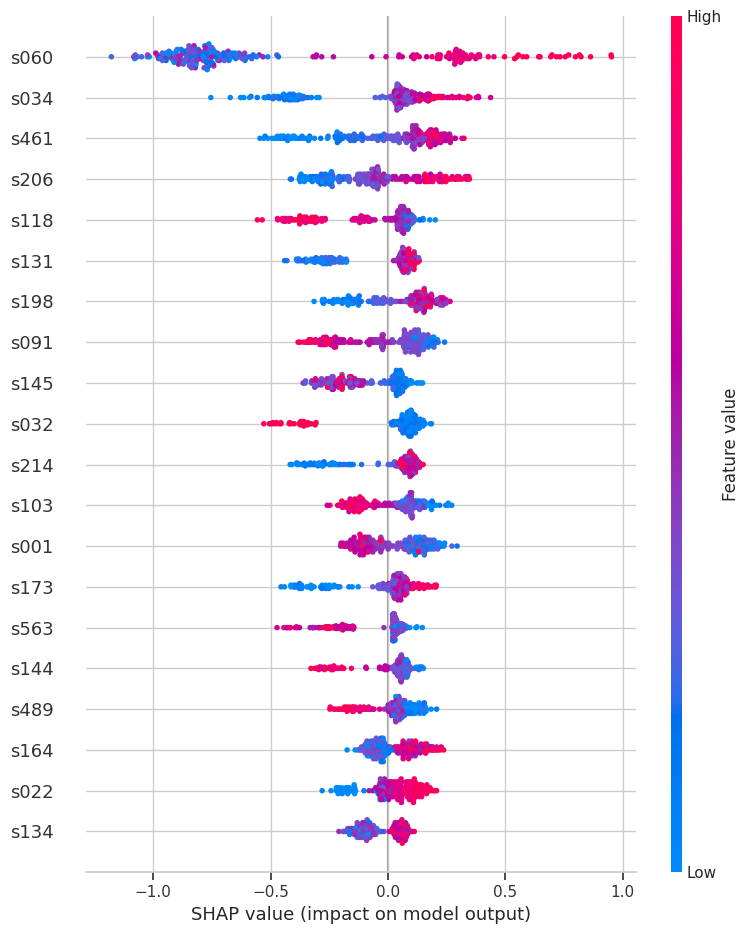

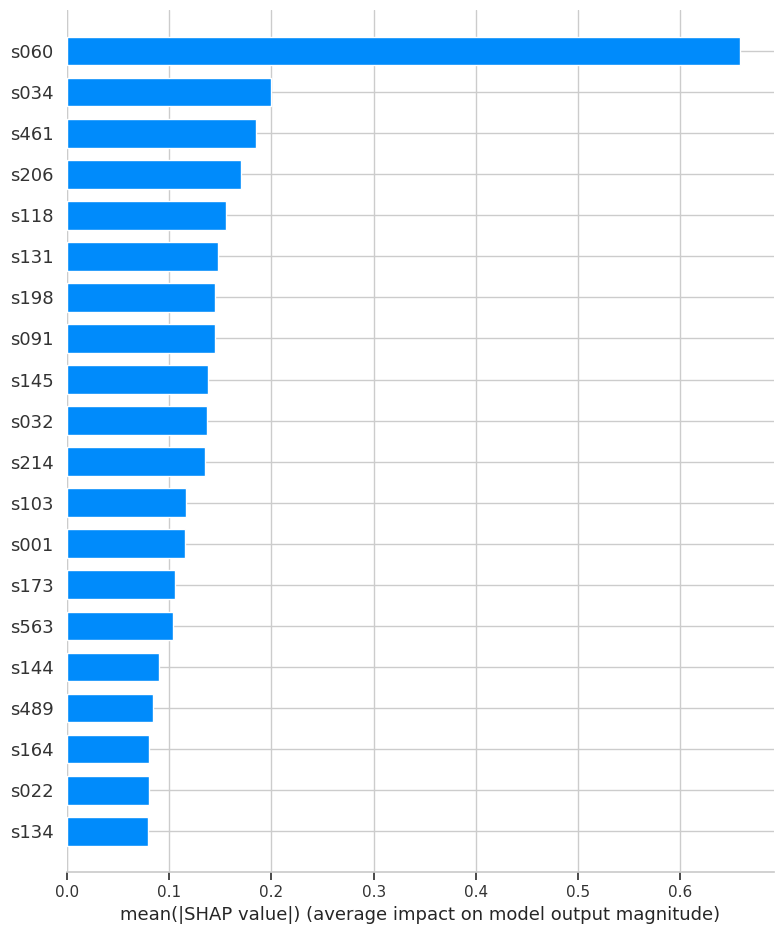

,0
s060,0.6586
s034,0.1994
s461,0.1845
s206,0.1700
s118,0.1553
s131,0.1478
s198,0.1449
s091,0.1447
s145,0.1383
s032,0.1373


In [12]:
Xt_train = pd.DataFrame(final[:-1].transform(X_train), columns=kept_names(final, X_train.columns))
Xt_test = pd.DataFrame(final[:-1].transform(X_test), columns=Xt_train.columns)

explainer = shap.Explainer(final[-1], shap.maskers.Independent(Xt_train, max_samples=200))
try:
    sv = explainer(Xt_test, check_additivity=False)
except TypeError:
    sv = explainer(Xt_test)
if sv.values.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv.values, Xt_test, show=False)
plt.tight_layout(); plt.savefig("results/figures/04_shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()
shap.summary_plot(sv.values, Xt_test, plot_type="bar", show=False)
plt.tight_layout(); plt.savefig("results/figures/05_shap_importance.png", dpi=150, bbox_inches="tight"); plt.show()

shap_rank = pd.Series(np.abs(sv.values).mean(axis=0), index=Xt_test.columns).sort_values(ascending=False)
shap_rank.head(10).round(4)

## 11. Save model, results and a summary to paste back

In [13]:
joblib.dump(final, "model/secom_failure_model.joblib")
import shutil; shutil.copy("transformers.py", "model/transformers.py")
with open("model/config.json", "w") as f:
    json.dump({"selected_model": best_name, "sensor_columns": list(X_all.columns), "alert_thresholds_by_cost_ratio": thresholds,
               "note": "Input = 590 sensor values per lot (NaN allowed). Output = failure probability."}, f, indent=2)

summary = {"dataset": "UCI SECOM (real semiconductor fab data)", "lots": int(len(X_all)), "sensors": int(X_all.shape[1]),
           "failure_rate_pct": round(float(y_all.mean()) * 100, 2),
           "split": split_info.astype(str).to_dict("records"),
           "cv_table": cv_table.round(4).to_dict("records"), "selected_model": best_name,
           "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
           "test_metrics": test_metrics, "gains_table": gains.to_dict("records"),
           "cost_table": cost_table.to_dict("records"), "top_shap_sensors": shap_rank.head(8).round(4).to_dict()}
with open("results/summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

with zipfile.ZipFile("project_outputs.zip", "w") as z:
    for folder in ["results", "model"]:
        for root, _, fs in os.walk(folder):
            for fn in fs:
                z.write(os.path.join(root, fn))

print(json.dumps(summary, indent=2, default=str))
try:
    from google.colab import files
    files.download("project_outputs.zip")
except ImportError:
    pass

{
  "dataset": "UCI SECOM (real semiconductor fab data)",
  "lots": 1567,
  "sensors": 590,
  "failure_rate_pct": 6.64,
  "split": [
    {
      "set": "train",
      "lots": "1096",
      "failures": "78",
      "failure_rate_pct": "7.12",
      "from": "2008-07-19 11:55:00",
      "to": "2008-09-26 02:26:00"
    },
    {
      "set": "validation",
      "lots": "235",
      "failures": "17",
      "failure_rate_pct": "7.23",
      "from": "2008-09-26 03:12:00",
      "to": "2008-10-05 18:59:00"
    },
    {
      "set": "test",
      "lots": "236",
      "failures": "9",
      "failure_rate_pct": "3.81",
      "from": "2008-10-05 19:45:00",
      "to": "2008-10-17 06:07:00"
    }
  ],
  "cv_table": [
    {
      "model": "XGBoost (tuned)",
      "cv_pr_auc": 0.19,
      "cv_pr_auc_std": 0.1372,
      "cv_roc_auc": 0.6857,
      "cv_roc_auc_std": 0.0984
    },
    {
      "model": "Random Forest",
      "cv_pr_auc": 0.1532,
      "cv_pr_auc_std": 0.0375,
      "cv_roc_auc": 0.6218,
  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>